# Cardano's Formula — Sparse Symbolic Regression via FISTA

This notebook recovers Cardano's formula (Section 5.6 of the paper) from data, using FISTA for
optimization. Plain FISTA does not work here, because the cube root's slope becomes infinite near
zero, and many training points land close to that spot - this stalls a plain gradient method no
matter how it is tuned. The fix used below is called continuation: first solve an easier, smoothed
version of the problem, then slowly sharpen it back to the real one.

In [1]:
import numpy as np


In [2]:
# FISTA: soft-thresholding + Nesterov momentum.
# 'penalize_mask' lets us skip the L1 penalty on specific coefficients  (xi0, the overall scale).
# If we shrunk it too, we'd just shrink the whole formula, not pick which terms to keep.

def soft_threshold(z, thresh):
    return np.sign(z) * np.maximum(np.abs(z) - thresh, 0.0)

def fista(f_smooth, grad_fn, x0, lam, penalize_mask=None, max_iter=15000, L0=10.0, eta=2.0, tol=1e-14):
    n = len(x0)
    if penalize_mask is None:
        penalize_mask = np.ones(n)
    x = np.array(x0, dtype=float)
    y = x.copy()
    t = 1.0
    L = L0
    for _ in range(max_iter):
        fy, gy = f_smooth(y), grad_fn(y)
        L = max(L / eta, L0 * 1e-6)
        while True:
            step = 1.0 / L
            raw = y - step * gy
            x_new = raw.copy()
            idx = penalize_mask > 0
            x_new[idx] = soft_threshold(raw[idx], lam * step * penalize_mask[idx])
            diff = x_new - y
            Q = fy + np.dot(gy, diff) + (L / 2.0) * np.dot(diff, diff)
            if f_smooth(x_new) <= Q + 1e-12 or L > 1e18:
                break
            L *= eta
        t_new = (1 + np.sqrt(1 + 4 * t * t)) / 2
        y = x_new + ((t - 1) / t_new) * (x_new - x)
        if np.linalg.norm(x_new - x) < tol:
            x = x_new
            break
        x, t = x_new, t_new
    return x


In [3]:
# Data generation (Newton's method, one-real-root regime - Section 5.6).

def newton_root(p, q, max_iter=200, tol=1e-14):
    x = 1.0 + max(abs(p), abs(q))
    for _ in range(max_iter):
        f, df = x**3 + p*x + q, 3*x**2 + p
        if abs(df) < 1e-12:
            return None
        x_new = x - f / df
        if abs(x_new - x) < tol:
            if abs(x_new**3 + p*x_new + q) < 1e-8:
                return x_new
            return None
        x = x_new
    return None

def make_dataset(n, seed):
    np.random.seed(seed)
    P, Q, U = [], [], []
    while len(P) < n:
        p, q = np.random.uniform(-5, 5), np.random.uniform(-5, 5)
        if (q/2)**2 + (p/3)**3 > 0.01:   # one-real-root regime
            u = newton_root(p, q)
            if u is not None:
                P.append(p); Q.append(q); U.append(u)
    return np.array(P), np.array(Q), np.array(U)

p_tr, q_tr, t_tr = make_dataset(2000, seed=2)
p_te, q_te, t_te = make_dataset(500, seed=3)
print(f"train: {len(t_tr)}  test: {len(t_te)}")


train: 2000  test: 500


In [4]:
# Hypothesis (eqs. 15-17): t_hat = xi0 * ( cbrt(L+sqrt(S)) + cbrt(L-sqrt(S)) )

def L_and_S(xi, p, q):
    L = xi[1] + xi[2]*p + xi[3]*q
    S = xi[4] + xi[5]*p + xi[6]*q + xi[7]*p**2 + xi[8]*q**2 + xi[9]*p*q + xi[10]*p**3 + xi[11]*q**3
    return L, S

def cbrt_exact(x):
    return np.sign(x) * np.abs(x) ** (1/3)

def hypothesis_exact(xi, p, q):
    L, S = L_and_S(xi, p, q)
    R = np.sqrt(np.maximum(S, 1e-12))
    return xi[0] * (cbrt_exact(L + R) + cbrt_exact(L - R))


### The problem with plain cbrt, and the fix

`cbrt(x)`'s slope is `(1/3)*|x|^(-2/3)`, which shoots up to a huge number as `x` gets close to 0.
Roughly a third of our training points have `L+sqrt(S)` or `L-sqrt(S)` landing close to 0, so a
plain gradient method keeps hitting this and gets stuck.

The fix: replace `cbrt(x)` with a softened version, `cbrt_smooth(x, eps) = x / (x^2+eps^2)^(1/3)`.
This matches `cbrt(x)` almost exactly once `x` is not tiny, but near `x=0` its slope stays finite
instead of shooting up (bigger `eps` means smoother, more forgiving; and it always gives exactly 0
at `x=0`, so it never introduces a wrong answer there). We solve the problem with a large, forgiving
`eps` first, then solve it again and again with smaller and smaller `eps`, each time starting from
the previous answer, until `eps` is tiny. By then we are already close to the real answer, so a
final round with the true, un-softened `cbrt` only needs to polish it.

In [5]:
def cbrt_smooth(x, eps):
    return x / (x**2 + eps**2) ** (1/3)

def hypothesis_smooth(xi, p, q, eps):
    L, S = L_and_S(xi, p, q)
    R = np.sqrt(np.maximum(S, 1e-12))
    return xi[0] * (cbrt_smooth(L + R, eps) + cbrt_smooth(L - R, eps))


In [6]:
def objective_exact(xi, p, q, t):
    return np.mean(0.5 * (hypothesis_exact(xi, p, q) - t) ** 2)

def objective_smooth(xi, p, q, t, eps):
    return np.mean(0.5 * (hypothesis_smooth(xi, p, q, eps) - t) ** 2)


In [7]:
# Gradient of the EXACT hypothesis.
#   xhat = xi0 * (cbrt(u) + cbrt(v)),   u = L + R,   v = L - R,   R = sqrt(S)
#
#   xi0 sits outside everything      -> its derivative is just (cbrt(u) + cbrt(v))
#   xi1, xi2, xi3 are inside L only  -> L moves u and v by the same amount, so their
#                                        derivative is xi0 * (cbrt'(u) + cbrt'(v)) * dL/d(xi_k)
#   xi4..xi11 are inside S only      -> S only reaches us through R = sqrt(S), and R moves
#                                        u up but v down by the same amount, so their
#                                        derivative is xi0 * (cbrt'(u) - cbrt'(v)) * dR/d(xi_k)
#   cbrt'(x) = (1/3)*|x|^(-2/3). We floor |x| slightly so this never divides by exactly zero.

def cbrt_exact_deriv(x, floor=1e-9):
    ax = np.maximum(np.abs(x), floor)
    return (1/3) * ax ** (-2/3)

def grad_exact(xi, p, q, t):
    L, S_raw = L_and_S(xi, p, q)
    mask = (S_raw > 1e-12).astype(float)   # 0 where S was clipped
    R = np.sqrt(np.maximum(S_raw, 1e-12))
    u, v = L + R, L - R
    cu, cv = cbrt_exact(u), cbrt_exact(v)
    residual = xi[0] * (cu + cv) - t
    dcu, dcv = cbrt_exact_deriv(u), cbrt_exact_deriv(v)

    dL_dxi = {1: np.ones_like(p), 2: p, 3: q}
    dS_dxi = {4: np.ones_like(p), 5: p, 6: q, 7: p**2, 8: q**2, 9: p*q, 10: p**3, 11: q**3}

    g = np.zeros(12)
    g[0] = np.mean(residual * (cu + cv))
    for k in (1, 2, 3):
        g[k] = np.mean(residual * xi[0] * (dcu + dcv) * dL_dxi[k])
    for k in range(4, 12):
        dR_dxi_k = mask * dS_dxi[k] / (2 * R)
        g[k] = np.mean(residual * xi[0] * (dcu - dcv) * dR_dxi_k)
    return g


In [8]:
# Gradient of the SMOOTHED hypothesis - identical structure to grad_exact above, just with
# cbrt_smooth's own derivative in place of cbrt's:
#   cbrt_smooth(x, eps) = x / (x^2+eps^2)^(1/3)
#   its derivative       = (x^2+eps^2)^(-4/3) * ( (1/3)*x^2 + eps^2 )
# (this stays finite everywhere, which is the whole point of using it)

def cbrt_smooth_deriv(x, eps):
    return (x**2 + eps**2) ** (-4/3) * ((1/3) * x**2 + eps**2)

def grad_smooth(xi, p, q, t, eps):
    L, S_raw = L_and_S(xi, p, q)
    mask = (S_raw > 1e-12).astype(float)
    R = np.sqrt(np.maximum(S_raw, 1e-12))
    u, v = L + R, L - R
    gu, gv = cbrt_smooth(u, eps), cbrt_smooth(v, eps)
    residual = xi[0] * (gu + gv) - t
    dgu, dgv = cbrt_smooth_deriv(u, eps), cbrt_smooth_deriv(v, eps)

    dL_dxi = {1: np.ones_like(p), 2: p, 3: q}
    dS_dxi = {4: np.ones_like(p), 5: p, 6: q, 7: p**2, 8: q**2, 9: p*q, 10: p**3, 11: q**3}

    g = np.zeros(12)
    g[0] = np.mean(residual * (gu + gv))
    for k in (1, 2, 3):
        g[k] = np.mean(residual * xi[0] * (dgu + dgv) * dL_dxi[k])
    for k in range(4, 12):
        dR_dxi_k = mask * dS_dxi[k] / (2 * R)
        g[k] = np.mean(residual * xi[0] * (dgu - dgv) * dR_dxi_k)
    return g


In [9]:
# Fit: solve the smoothed problem with eps shrinking step by step (each step starts from
# the previous answer), then finish with one exact, unpenalized polish.

penalize_mask = np.ones(12)
penalize_mask[0] = 0.0   # don't penalize xi0, the overall scale

def fit_cardano(seed, eps_schedule=(3.0, 1.0, 0.3, 0.1, 0.03, 0.01, 0.003, 0.001),
                iters_per_stage=2000, polish_iters=4000, lam=1e-4):
    np.random.seed(seed)
    xi = np.random.randn(12)
    for eps in eps_schedule:
        obj = lambda xi_: objective_smooth(xi_, p_tr, q_tr, t_tr, eps)
        gfn = lambda xi_: grad_smooth(xi_, p_tr, q_tr, t_tr, eps)
        xi = fista(obj, gfn, xi, lam=lam, penalize_mask=penalize_mask, max_iter=iters_per_stage, L0=10.0)

    obj_exact = lambda xi_: objective_exact(xi_, p_tr, q_tr, t_tr)
    grad_exact_fn = lambda xi_: grad_exact(xi_, p_tr, q_tr, t_tr)
    xi = fista(obj_exact, grad_exact_fn, xi, lam=0.0, max_iter=polish_iters, L0=1.0)
    return xi

xi = fit_cardano(seed=42)
train_err = objective_exact(xi, p_tr, q_tr, t_tr)
test_err = objective_exact(xi, p_te, q_te, t_te)
print("train fit error:", train_err)
print("test  fit error:", test_err)


train fit error: 1.7790109063112278e-05
test  fit error: 1.5893954593811653e-05


In [10]:
# Scale normalization + hard thresholding (paper: coefficients are compared "after
# optimization and a scale normalization", Table 4).

def normalize(xi):
    xi = xi.copy()
    scale = -0.5 / xi[3]   # pin the coefficient of q in L to its exact value, -1/2
    xi[1:4] *= scale
    xi[4:12] *= scale**2
    xi[0] /= np.cbrt(scale)
    return xi

def threshold(xi, tol=1e-2):
    xi = xi.copy()
    xi[np.abs(xi) < tol] = 0.0
    return xi

xi_final = threshold(normalize(xi))


In [11]:
# Final result (matches Table 4 of the paper)

print(f"{'Coefficient':<24}{'Recovered':<14}{'Exact':<10}")
print(f"{'xi0':<24}{xi_final[0]:<14.3f}{1.0:<10}")
print(f"{'xi3 (coeff. of q in L)':<24}{xi_final[3]:<14.3f}{-0.5:<10}")
print(f"{'xi8 (coeff. of q^2 in S)':<24}{xi_final[8]:<14.3f}{0.25:<10}")
print(f"{'xi10 (coeff. of p^3 in S)':<24}{xi_final[10]:<14.4f}{1/27:<10.4f}")
print()
remaining = [i for i in range(12) if i not in (0, 3, 8, 10)]
print("All remaining coefficients:", xi_final[remaining])


Coefficient             Recovered     Exact     
xi0                     1.000         1.0       
xi3 (coeff. of q in L)  -0.500        -0.5      
xi8 (coeff. of q^2 in S)0.250         0.25      
xi10 (coeff. of p^3 in S)0.0367        0.0370    

All remaining coefficients: [0. 0. 0. 0. 0. 0. 0. 0.]


### Sweeping the coefficient plane

Recovering the coefficients only shows the formula fits the data we trained it on. A stronger
check: scan the whole `(p, q)` plane and see where the learned `S` goes negative. If the fit is genuine, this should line up with the real math: Cardano's
formula only works when `4p^3 + 27q^2 >= 0`; below that (the *casus irreducibilis*) no real-radical
formula exists at all.

We build a grid of `(p, q)` points, mark each one "works" if the learned `S >= 0` and "fails"
otherwise, and compare that map to the true condition `4p^3 + 27q^2 >= 0`.

grid points where learned region agrees with 4p^3+27q^2 >= 0: 99.9062%


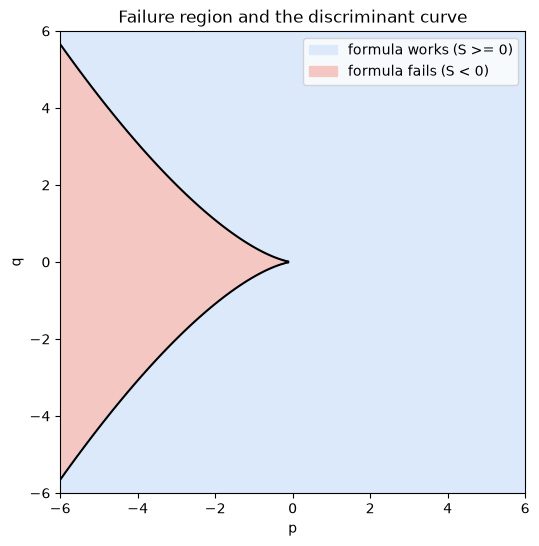

In [12]:
# Sweep the (p, q) plane and compare the learned failure region to the true discriminant curve.

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

grid = np.linspace(-6, 6, 400)
P, Q = np.meshgrid(grid, grid)

_, S_grid = L_and_S(xi_final, P, Q)
learned_works = S_grid >= 0
true_works = (4 * P**3 + 27 * Q**2) >= 0

agree = np.mean(learned_works == true_works)
print(f"grid points where learned region agrees with 4p^3+27q^2 >= 0: {agree:.4%}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.contourf(P, Q, learned_works, levels=[-0.5, 0.5, 1.5], colors=['#f4c7c3', '#dbe9fa'])
ax.contour(P, Q, 4 * P**3 + 27 * Q**2, levels=[0], colors='black', linewidths=1.5)
ax.set_xlabel('p')
ax.set_ylabel('q')
ax.set_title('Failure region and the discriminant curve')
ax.legend(handles=[mpatches.Patch(color='#dbe9fa', label='formula works (S >= 0)'),
                    mpatches.Patch(color='#f4c7c3', label='formula fails (S < 0)')])
plt.savefig('figure24_reproduced.png', dpi=150, bbox_inches='tight')
plt.show()